# 项目1 · 游戏运营数据分析（Gamelytics）

按顺序从上往下跑。跑完记得看 `figures/` 里生成的图，面试时可以对着讲。

In [1]:
# ① 环境变量（每次重启内核后必须先跑这一格）
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"      # 修复 Anaconda OpenMP 冲突
os.environ["PYTHONIOENCODING"] = "utf-8"          # 中文不乱码
os.environ["HF_HUB_OFFLINE"] = "1"                # 模型走本地缓存，不联网
os.environ["TRANSFORMERS_OFFLINE"] = "1"
print("环境变量已设置")
print("如果后面报 OMP: Error #15，说明有库已经提前加载了，重启内核后再跑这一格")

环境变量已设置
如果后面报 OMP: Error #15，说明有库已经提前加载了，重启内核后再跑这一格


In [2]:
# ② 切到项目根目录（脚本里的相对路径都依赖这个）
import os
os.chdir(r"D:/Projects/gamelytics_analysis")
print("当前目录:", os.getcwd())

当前目录: D:\Projects\gamelytics_analysis


## 准备：看图小工具（跑一次即可）

In [3]:
from IPython.display import Image, display
import glob

def show(prefix):
    """显示 figures/ 下以 prefix 开头的所有图"""
    files = sorted(glob.glob(f"figures/{prefix}*.png"))
    if not files:
        print("没有找到图，检查上一步是否报错")
    for f in files:
        print(f)
        display(Image(f))

## 1. 模块1：运营健康度

模块 1：运营健康度

[注册] 累计注册用户 1,000,000，时间跨度 1998-11-18 ~ 2020-09-23



[活跃] 近 365 天（2019-09-24 ~ 2020-09-23）
  日均 DAU : 11,883
  峰值 DAU : 15,948
  平均周活 : 50,733
  平均月活 : 76,092
  平均粘性 DAU/MAU : 16.2%

[趋势] DAU 前90天均值 9,339 → 后90天均值 14,686，增长 +57.2%



[图表] 已保存到 figures/ 目录
figures\01_activity_trend.png


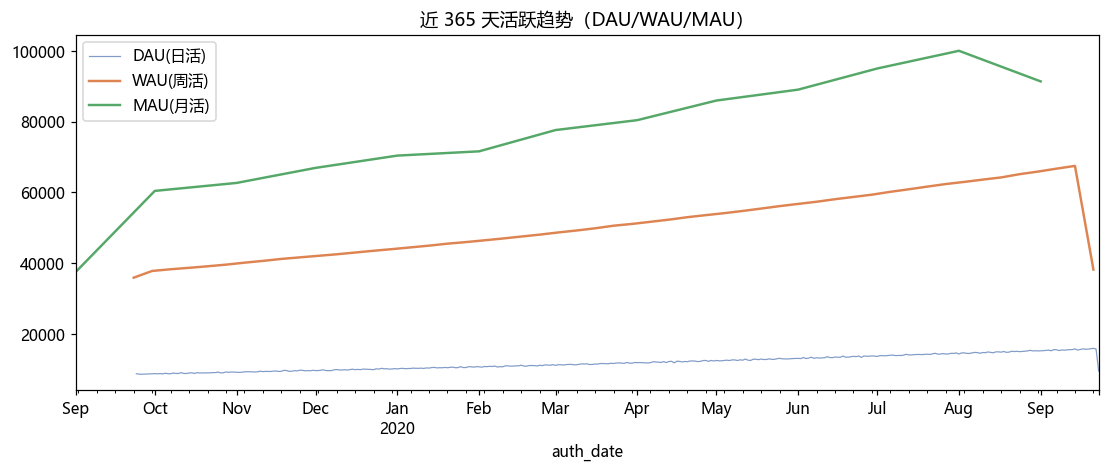

figures\01_registration_growth.png


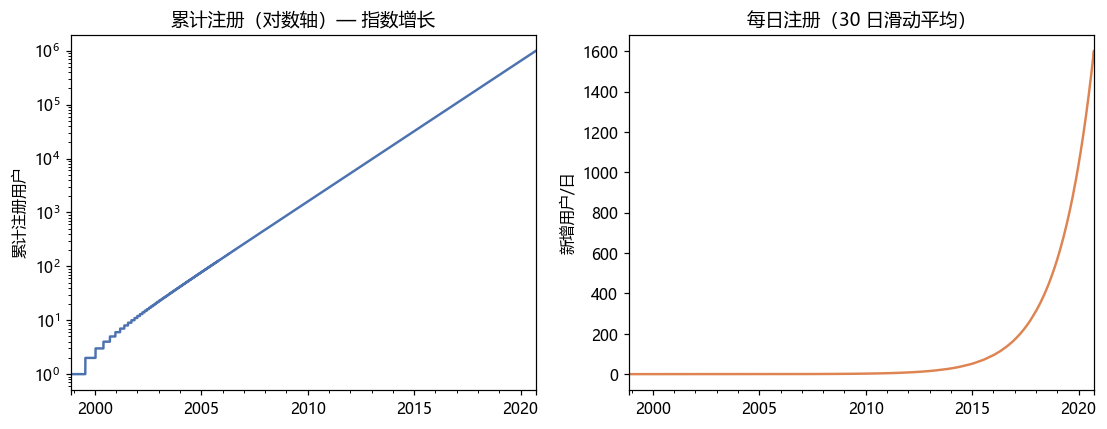

figures\01_stickiness.png


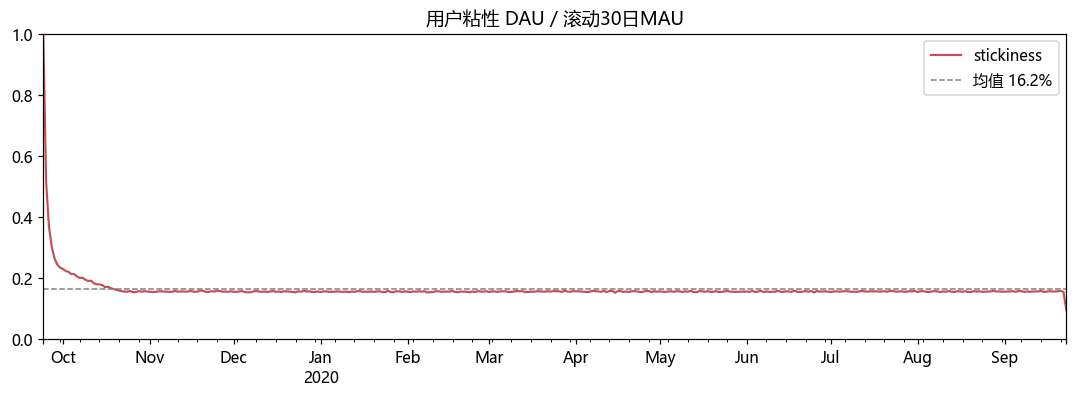

In [4]:
%run analysis/01_health.py
show("01_")

## 2. 模块2：留存分析

模块 2：留存分析（严格 + 累计两种口径）



[留存对比]（已处理右删失）
  节点     严格(当天登录)         累计(N天内回来)       
  D1              2.01%            2.01%
  D3              4.65%           10.06%
  D7              5.88%           23.99%
  D14             4.57%           23.99%
  D30             2.83%           23.99%



[Cohort 留存矩阵] 近 12 个注册月（D1~D30，NaN=右删失）
           总用户     D1     D3     D7    D14    D30
cohort                                           
2019-10  28998  0.021  0.043  0.056  0.047  0.028
2019-11  29505  0.020  0.046  0.060  0.046  0.028
2019-12  32057  0.020  0.047  0.060  0.045  0.028
2020-01  33733  0.020  0.048  0.057  0.044  0.027
2020-02  33152  0.020  0.044  0.056  0.045  0.027
2020-03  37231  0.020  0.047  0.058  0.045  0.028
2020-04  37884  0.021  0.046  0.059  0.046  0.029
2020-05  41159  0.019  0.046  0.059  0.046  0.030
2020-06  41880  0.019  0.046  0.057  0.046  0.028
2020-07  45502  0.020  0.047  0.058  0.046  0.028
2020-08  47882  0.020  0.046  0.060  0.046  0.028
2020-09  36540  0.021  0.045  0.058  0.045    NaN

[趋势] D7 留存：最早 5.65% → 最新 5.76%（基本持平=留存质量没提升）



[图表] 已保存到 figures/
figures\02_cohort_heatmap.png


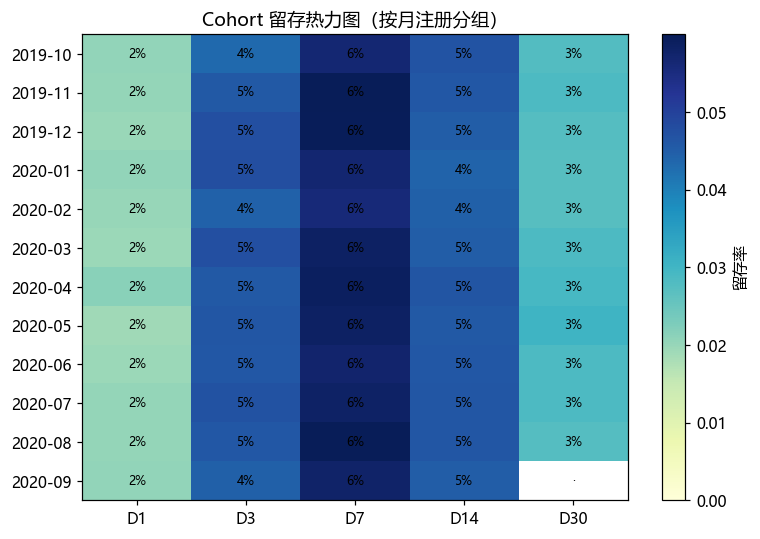

figures\02_retention_curve.png


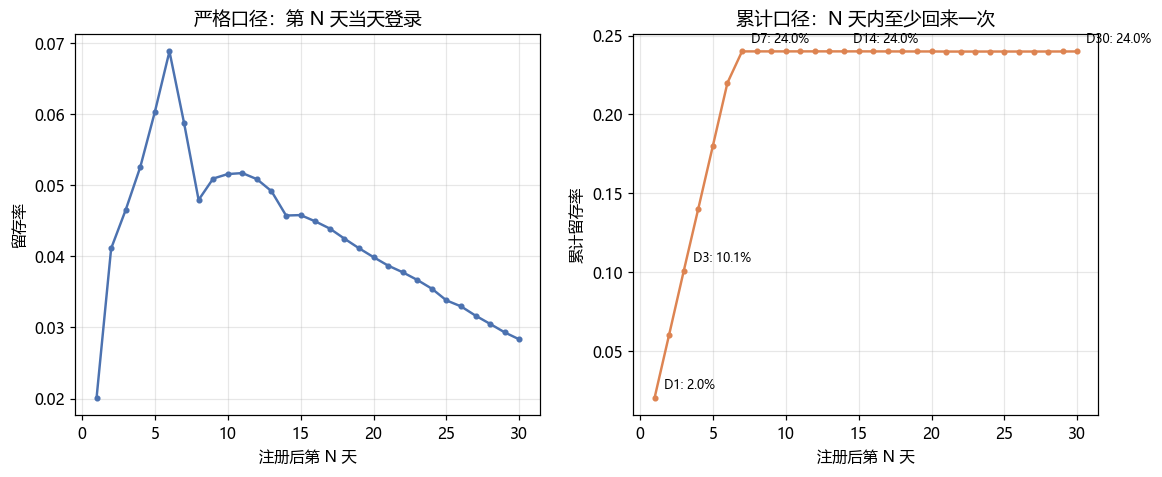

In [5]:
%run analysis/02_retention.py
show("02_")

## 3. 模块3：付费变现

模块 3：付费变现

[付费概览]
  总用户       : 404,770
  付费用户     : 3,733
  付费率       : 0.92%
  总收入       : 10,557,792
  ARPU(人均)   : 26.08
  ARPPU(付费人均): 2828.23  ← 是 ARPU 的 108 倍
  revenue中位数 : 0（中位数=0，说明绝大多数人没付费）

[大中小R 分层]
              分层     人数   人数占比      收入   收入占比         人均
             非付费 401037 0.9908       0 0.0000     0.0000
     小额付费(≤1000)   1805 0.0045  545937 0.0517   302.4582
中额付费(1000~10000)   1805 0.0045 5421603 0.5135  3003.6582
 大额付费/鲸鱼(>10000)    123 0.0003 4590252 0.4348 37319.1220
  → 结论：0.03% 的鲸鱼，贡献了 43.48% 的收入

[收入集中度(帕累托)]
  前1%用户            贡献 100.00% 的收入
  前2%用户            贡献 100.00% 的收入
  前5%用户            贡献 100.00% 的收入
  前10%用户           贡献 100.00% 的收入
  付费玩家里前1%贡献       贡献 13.09% 的收入



[A/B 测试 a vs b]
  付费率: A=0.9540%  B=0.8906%  (z=2.1, p=0.0350)
  ARPU : A=25.4137  B=26.7513  差=-1.3376
  ARPU差 95%CI: [-5.4825, 3.1500]  (Mann-Whitney p=0.0627)



[付费 vs 活跃度]
     mean  median   count
非付费  15.6     1.0  401037
付费   16.2     1.0    3733



[图表] 已保存到 figures/
figures\03_ab_test.png


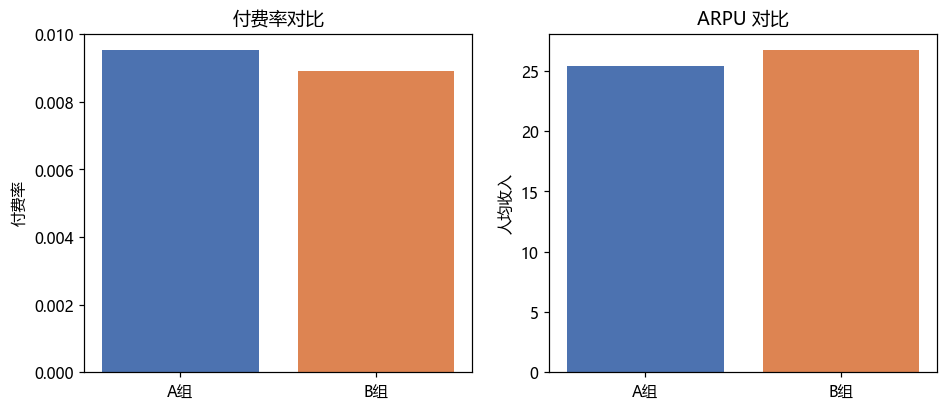

figures\03_revenue_longtail.png


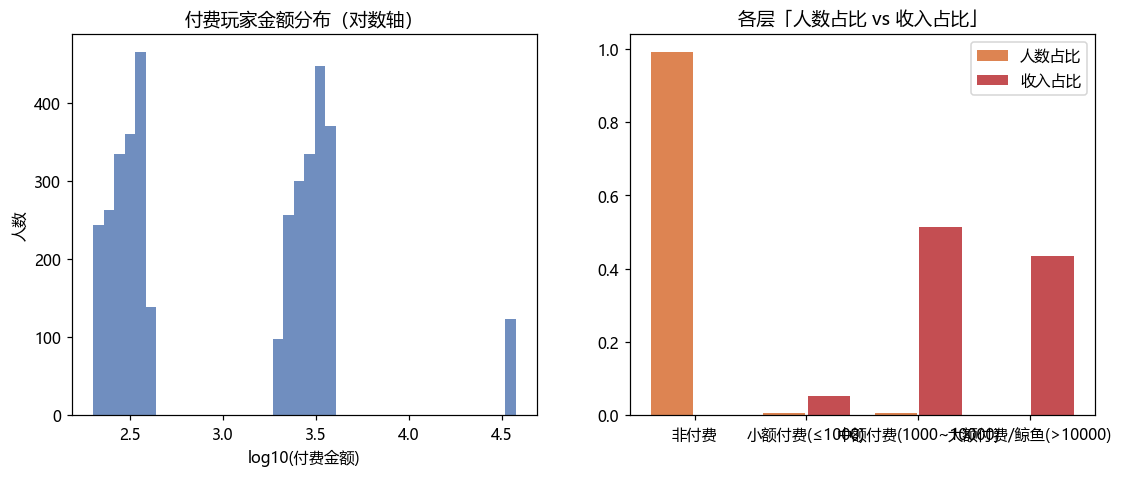

In [6]:
%run analysis/03_monetization.py
show("03_")

## 4. 模块4：用户分群

模块 4：用户分群（RFM + K-Means）



[RFM 业务分群]（R=最近活跃，F=登录频次，M=是否付费）
              人数  付费率      人均收入  平均登录次数   人数占比
rfm                                           
完全流失       39817  0.0     0.000   0.000  0.098
待挽留付费客户     1466  1.0  2914.819   2.033  0.004
沉睡付费客户       398  1.0  2162.794   0.000  0.001
活跃潜力客户    200569  0.0     0.000  29.460  0.496
流失中的活跃用户  160651  0.0     0.000   2.055  0.397
重要价值客户      1869  1.0  2902.020  30.788  0.005



[K-Means 肘部] k=2..8 的 inertia: ['1,041,829', '658,713', '298,845', '138,765', '98,081', '80,212', '62,658']



[K-Means 聚类（k=5）各簇画像]
             人数    付费率      人均收入   平均登录次数   平均活跃天数   平均距今未登录
cluster                                                     
0        342614  0.000     0.000    2.100    2.100  1210.622
1          3653  0.008     8.839  546.148  546.148     1.255
2          3699  1.000  2845.264   11.327   11.327  1894.312
3         14479  0.000     0.060  244.637  244.637     1.275
4         40325  0.000     0.000    0.027    0.027  7943.704



[图表] 已保存到 figures/
figures\04_segmentation.png


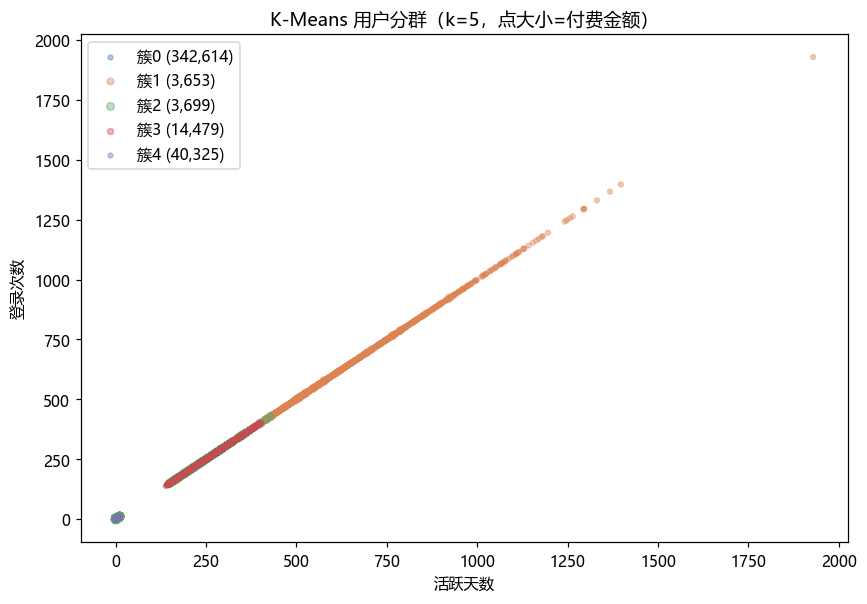

In [7]:
%run analysis/04_segmentation.py
show("04_")

## 5. 模块5：流失预测（最慢，2-5分钟）

模块 5：流失预测（行为特征 → 是否会流失）



[人群漏斗]
  可观测用户(注册满28天)        : 955,571
  建模人群(观察期day0-13登录过) : 955,571（合成数据每个用户注册当天都登录）
  建模人群流失率(第14天后不再登录) : 81.67%
  → 基准流失率高达 82%，典型高流失游戏（与模块2的76%注册即流失呼应）

[特征冗余检查]
  login_cnt == active_days 的比例 : 100.0%
  login_cnt / active_days 恒等于 : True
  first_login_lag 恒等于 0        : 100.0%
  → 合成数据每天只登录1次，登录强度/首次滞后都是常数，无区分度，故剔除；
     最终只保留 3 个独立特征：体量 / 近期性 / 连续性。

[特征] 3 个独立行为特征，样本 955,571

[模型对比] 5 折交叉验证 ROC-AUC


  逻辑回归(基线)         AUC = 0.9857 ± 0.0002


  XGBoost          AUC = 0.9859 ± 0.0002


  LightGBM         AUC = 0.9859 ± 0.0002

  → 最优模型：LightGBM（AUC=0.9859）
  注：AUC 偏高(≈0.99)是因为数据是合成生成的，流失信号很干净（近期没登录≈流失）。
      真实游戏里流失更随机，AUC 通常落在 0.7~0.85；这里重点看的是特征的相对重要性。



[SHAP 解释] 哪些行为最能预示流失？


login_cnt                0.0587
max_gap                  0.2485
days_since_last_login    9.9545

  （SHAP mean|value|，值越大越能区分流失/留存）

  → 结论：近期性(days_since_last_login)是流失的第一信号——
     用户越久没登录，流失概率越高。运营抓手：对「7 天未登录」的用户提前干预
     （召回 / 推送 / 礼包），而不是等 14 天才想起挽留。

[图表] 已保存到 figures/
figures\05_churn_roc.png


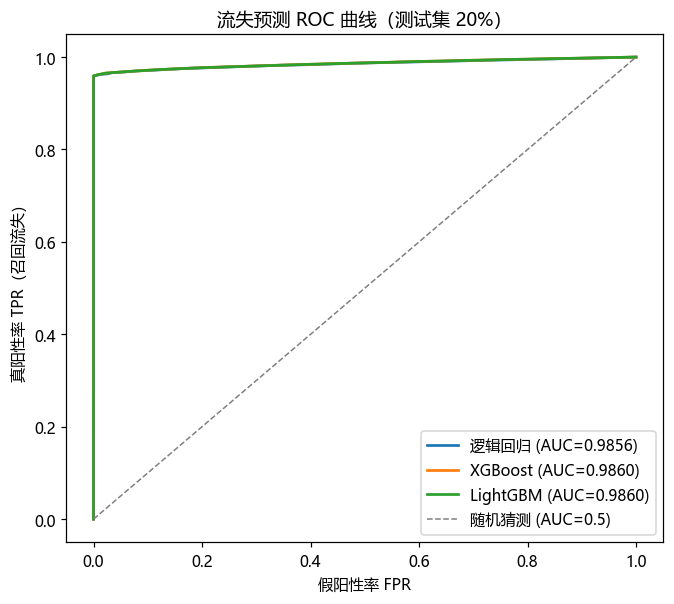

figures\05_churn_shap.png


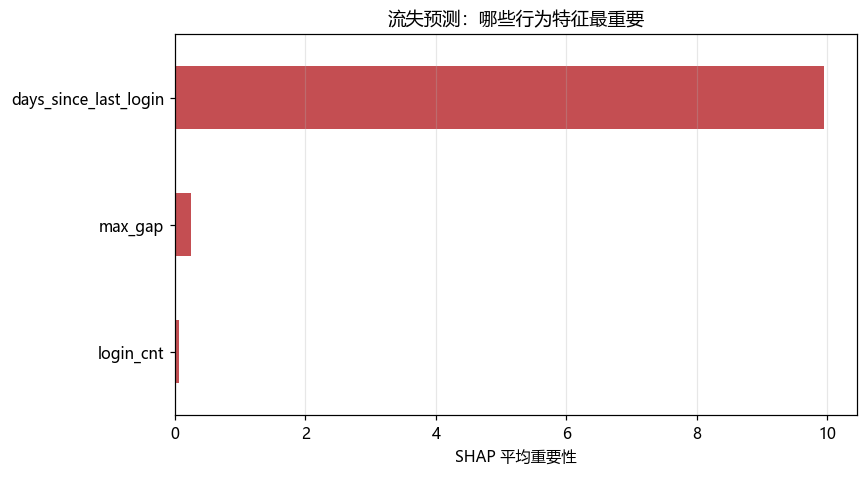

In [8]:
%run analysis/05_churn.py
show("05_")

## 6. 模块6：结论建议

模块 6：结论建议（一页诊断）

[核心数字]
  严格留存     : D1=2.0%  D7=5.9%  D30=2.8%  ← 第1天断崖
  付费率       : 0.92%  ARPU=26.08  ARPPU=2828.23
  鲸鱼集中度   : 前 0.03% 的用户贡献 43.5% 的收入
  用户构成     : 活跃(30天内) 10.3%  |  流失 89.7%
  流失驱动     : 留存组距上次登录 1.9 天 vs 流失组 12.5 天

[因果链] 拉新驱动增长 → 留存质量不涨 → 付费极低且集中 → 付费用户整体沉睡 → 90%盘面已流失
  → 近期性(多久没登录)是流失的第一信号，7 天未登录就该干预。

[行动建议（按优先级）]
  P0 止血 : ①召回沉睡付费用户(鲸鱼0.03%贡献43.5%收入，付费用户中位已沉睡2.7年) ②上线7天未登录实时预警
  P1 留存 : ③修D1留存(首日体验/次日回访奖励) ④破冰付费(3.6%高频白嫖是转化金矿)
  P2 提质 : ⑤提升留存质量(cohort D7五年持平=产品力没提升) ⑥A/B扩样本再验证ARPU



[图表] 已保存到 figures/06_dashboard.png
figures\06_dashboard.png


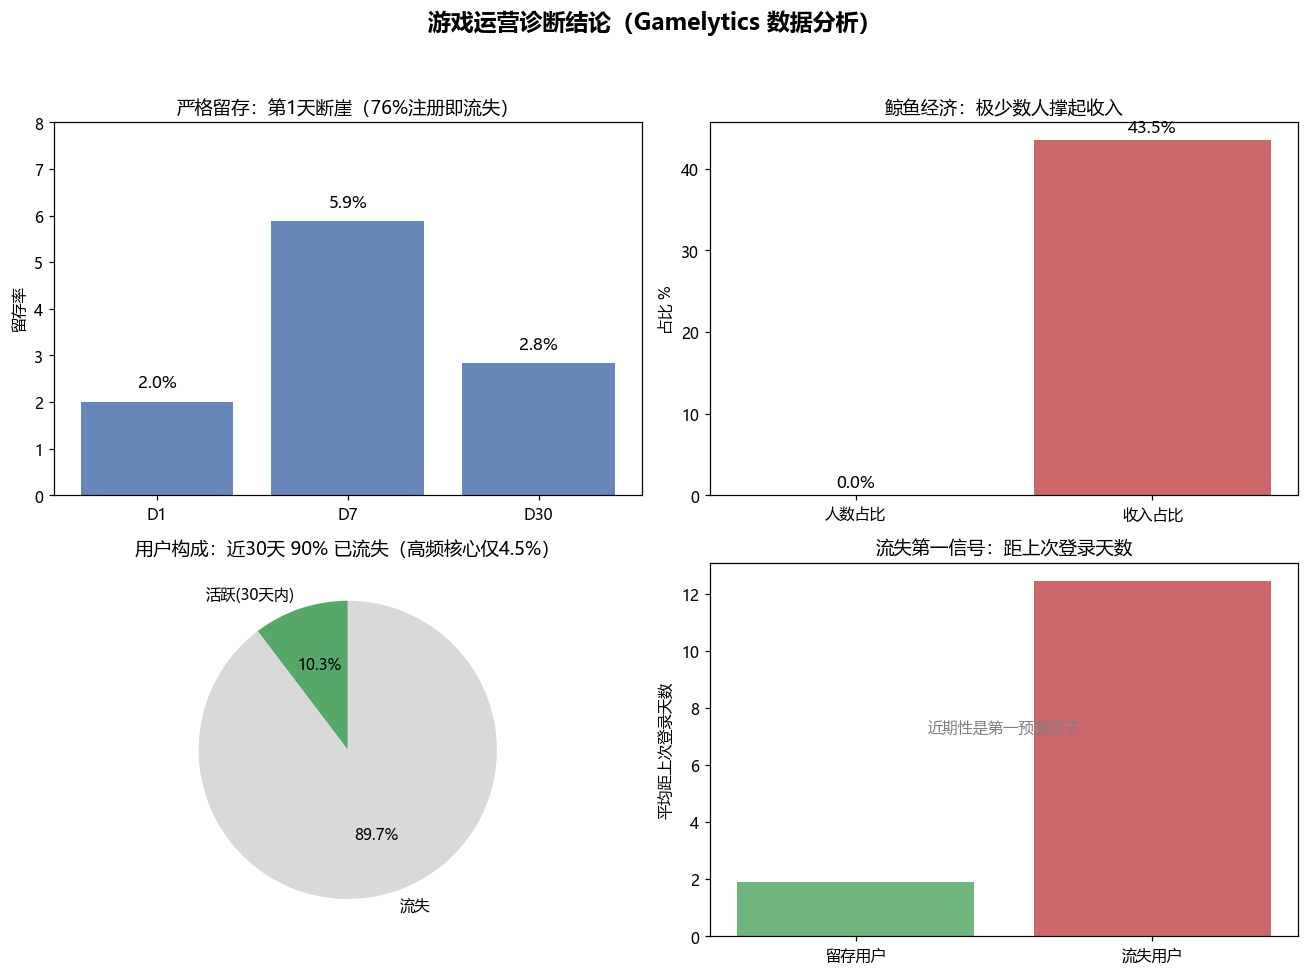

In [9]:
%run analysis/06_conclusion.py
show("06_")